# 半高全宽（Full Width at Half Maximum, FWHM）

> 来源：Weisstein, Eric W. "Full Width at Half Maximum." From *MathWorld*—A Wolfram Resource.
> <https://mathworld.wolfram.com/FullWidthatHalfMaximum.html>
>
> 本文为根据该页面整理的笔记（公式与要点）加演示代码。

## 定义

FWHM 用来描述曲线上一个"峰"有多宽：先找到峰的最大值 $f_{\max}$，再找峰两侧函数值降到 $f_{\max}/2$ 的两个点 $x_1 < x_2$，两点间的距离就是 FWHM：

$$
f(x_1) = f(x_2) = \tfrac{1}{2} f_{\max}, \qquad \mathrm{FWHM} = x_2 - x_1
$$

对于关于 $x=0$ 对称的峰，只要解出 $f(x_{1/2}) = \tfrac12 f(0)$，就有 $\mathrm{FWHM} = 2x_{1/2}$。半高半宽（HWHM）是 FWHM 的一半。

## 常见函数的 FWHM

原页面列出了几种常见曲线的 FWHM，大部分是切趾函数（apodization function / 窗函数，定义在 $|x| \le a$ 上）。

| 函数 | 表达式 | FWHM | 推导 |
|---|---|---|---|
| Bartlett（三角窗） | $1-\dfrac{\lvert x\rvert}{a}$ | $a$ | $x_{1/2}=a/2$ |
| Blackman | $0.42+0.5\cos\dfrac{\pi x}{a}+0.08\cos\dfrac{2\pi x}{a}$ | $\approx 0.810957\,a$ | 无简单闭式，需数值求解 |
| Connes | $\left(1-\dfrac{x^2}{a^2}\right)^2$ | $\sqrt{4-2\sqrt2}\,a$ | $1-x^2/a^2 = 1/\sqrt2$ |
| Cosine | $\cos\dfrac{\pi x}{2a}$ | $\dfrac43 a$ | $\pi x/(2a) = \pi/3$ |
| Gaussian | $e^{-x^2/(2\sigma^2)}$ | $2\sqrt{2\ln2}\,\sigma \approx 2.3548\,\sigma$ | $x^2 = 2\sigma^2\ln2$ |
| Hamming | $0.54+0.46\cos\dfrac{\pi x}{a}$ | $\approx 1.05543\,a$ | $\cos(\pi x/a) = -0.04/0.46$ |
| Hanning（Hann） | $\tfrac12\left[1+\cos\dfrac{\pi x}{a}\right]$ | $a$ | $\cos(\pi x/a)=0$ |
| Lorentzian | $\dfrac{\frac12\Gamma}{x^2+\left(\frac12\Gamma\right)^2}$ | $\Gamma$ | $x^2 = (\Gamma/2)^2$ |
| Welch | $1-\dfrac{x^2}{a^2}$ | $\sqrt2\,a$ | $x^2 = a^2/2$ |

注：原页面的表格没有给出 Blackman 窗的表达式，表中写的是常用的标准 Blackman 窗；下面的数值计算表明它给出的 FWHM 正是 $0.810957a$。

几点观察：

- FWHM 只取决于峰的形状，和峰的高度无关，所以函数乘上常数（比如归一化系数）不会改变 FWHM。
- 高斯函数的 FWHM 和标准差的关系 $\mathrm{FWHM} = 2\sqrt{2\ln2}\,\sigma \approx 2.3548\sigma$ 在谱峰拟合里经常用到。
- 洛伦兹函数的参数 $\Gamma$ 本身就是 FWHM。
## 演示代码

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


def fwhm_numeric(f, x_peak=0.0, x_max=None, **kw):
    """数值求单峰函数 f 的 FWHM：在峰两侧分别用 brentq 求 f(x) = f_max/2 的根。
    x_max 为搜索范围（窗函数取 a，无限支撑的函数取足够大的值）。"""
    half = f(x_peak, **kw) / 2
    g = lambda x: f(x, **kw) - half
    x_max = x_max if x_max is not None else 1e3
    left = brentq(g, x_peak - x_max, x_peak)
    right = brentq(g, x_peak, x_peak + x_max)
    return right - left

### 验证表格中的结果

In [10]:
a, sigma, Gamma = 1.0, 1.0, 1.0

windows = {
    "Bartlett":   (lambda x: 1 - np.abs(x) / a,                                       a),
    "Blackman":   (lambda x: 0.42 + 0.5 * np.cos(np.pi * x / a)
                              + 0.08 * np.cos(2 * np.pi * x / a),                     0.810957 * a),
    "Connes":     (lambda x: (1 - x**2 / a**2) ** 2,                                  np.sqrt(4 - 2 * np.sqrt(2)) * a),
    "Cosine":     (lambda x: np.cos(np.pi * x / (2 * a)),                             4 / 3 * a),
    "Hamming":    (lambda x: 0.54 + 0.46 * np.cos(np.pi * x / a),                     1.05543 * a),
    "Hanning":    (lambda x: 0.5 * (1 + np.cos(np.pi * x / a)),                       a),
    "Welch":      (lambda x: 1 - x**2 / a**2,                                         np.sqrt(2) * a),
    "Gaussian":   (lambda x: np.exp(-x**2 / (2 * sigma**2)),                          2 * np.sqrt(2 * np.log(2)) * sigma),
    "Lorentzian": (lambda x: (Gamma / 2) / (x**2 + (Gamma / 2) ** 2),                 Gamma),
}

print(f"{'函数':<12}{'数值 FWHM':>12}{'表中结果':>12}")
for name, (f, expected) in windows.items():
    # 窗函数只在 |x| <= a 上有意义，搜索范围取 a；高斯、洛伦兹取大一些
    x_max = a if name not in ("Gaussian", "Lorentzian") else 50
    print(f"{name:<12}{fwhm_numeric(f, 0.0, x_max):>12.6f}{expected:>12.6f}")

函数               数值 FWHM        表中结果
Bartlett        1.000000    1.000000
Blackman        0.810957    0.810957
Connes          1.082392    1.082392
Cosine          1.333333    1.333333
Hamming         1.055428    1.055430
Hanning         1.000000    1.000000
Welch           1.414214    1.414214
Gaussian        2.354820    2.354820
Lorentzian      1.000000    1.000000


### 画出窗函数和它们的半高位置

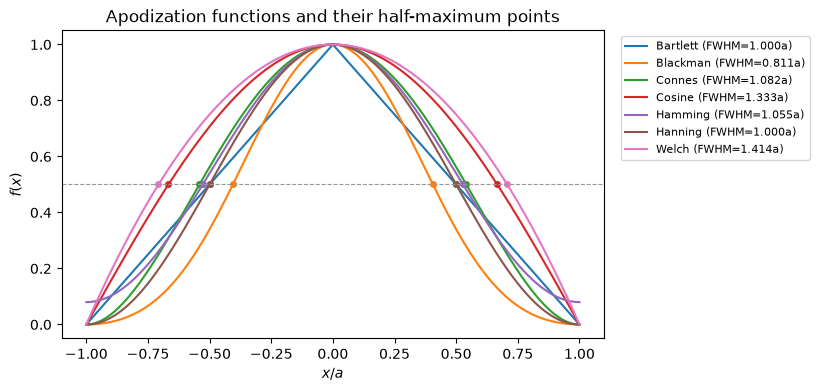

In [11]:
x = np.linspace(-a, a, 1001)
fig, ax = plt.subplots(figsize=(7, 4))
for name in ("Bartlett", "Blackman", "Connes", "Cosine", "Hamming", "Hanning", "Welch"):
    f, w = windows[name]
    line, = ax.plot(x, f(x), label=f"{name} (FWHM={w:.3f}a)")
    ax.plot([-w / 2, w / 2], [f(0) / 2] * 2, "o", ms=4, color=line.get_color())
ax.axhline(0.5, color="0.6", ls="--", lw=0.8)
ax.set_xlabel("$x/a$")
ax.set_ylabel("$f(x)$")
ax.set_title("Apodization functions and their half-maximum points")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))  # 图例放在图外，避免遮挡曲线
plt.show()

### 示意图：高斯和洛伦兹的 FWHM

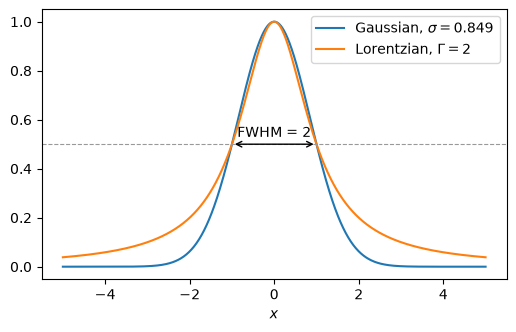

In [12]:
fwhm = 2.0
sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
x = np.linspace(-5, 5, 1001)
g = np.exp(-x**2 / (2 * sigma**2))
l = (fwhm / 2) ** 2 / (x**2 + (fwhm / 2) ** 2)  # 峰值化为 1 方便比较

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x, g, label=rf"Gaussian, $\sigma={sigma:.3f}$")
ax.plot(x, l, label=r"Lorentzian, $\Gamma=2$")
ax.annotate("", xy=(fwhm / 2, 0.5), xytext=(-fwhm / 2, 0.5),
            arrowprops=dict(arrowstyle="<->", color="k"))
ax.text(0, 0.53, "FWHM = 2", ha="center")
ax.axhline(0.5, color="0.6", ls="--", lw=0.8)
ax.set_xlabel("$x$")
ax.legend()
plt.show()

## 实际应用：从离散谱数据求 FWHM

做 XRD、Raman、XPS 时，数据是离散采样点，可以用 `scipy.signal.peak_widths` 求 FWHM（`rel_height=0.5` 就是半高处）。它会在采样点之间做线性插值，所以采样足够密时结果很准；要注意它是以"峰值减去峰两侧的最低点"作为峰高，有背景时最好先扣背景。

峰位  30.15  FWHM = 3.981  (真值 4.0)
峰位  64.70  FWHM = 7.957  (真值 8.0)


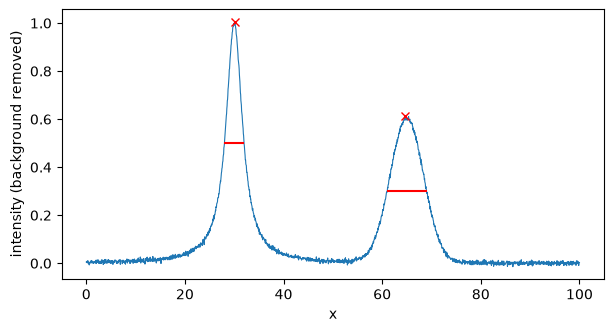

In [13]:
from scipy.signal import find_peaks, peak_widths

# 构造一条模拟谱：两个峰 + 线性背景 + 噪声
rng = np.random.default_rng(0)
x = np.linspace(0, 100, 2001)
dx = x[1] - x[0]
true_fwhm = {30: 4.0, 65: 8.0}
y = (1.0 * (2.0) ** 2 / ((x - 30) ** 2 + 2.0**2)                       # 洛伦兹峰，FWHM=4
     + 0.6 * np.exp(-((x - 65) ** 2) / (2 * (8 / 2.3548) ** 2))       # 高斯峰，FWHM=8
     + 0.002 * x + 0.05
     + rng.normal(0, 0.005, x.size))

y_corr = y - (0.002 * x + 0.05)  # 实际中需要用拟合等方法估计背景，这里直接扣掉已知背景

peaks, _ = find_peaks(y_corr, height=0.2, distance=200)
widths, width_heights, left_ips, right_ips = peak_widths(y_corr, peaks, rel_height=0.5)

for p, w in zip(peaks, widths):
    center = min(true_fwhm, key=lambda c: abs(c - x[p]))  # 对应的真实峰
    print(f"峰位 {x[p]:6.2f}  FWHM = {w * dx:.3f}  (真值 {true_fwhm[center]})")
# 结果略小于真值：噪声让最高点偏高，峰的形状也受相邻峰拖尾的影响。精确测量 FWHM 应该做峰拟合

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, y_corr, lw=0.8)
ax.hlines(width_heights, x[0] + left_ips * dx, x[0] + right_ips * dx, color="red")
ax.plot(x[peaks], y_corr[peaks], "x", color="red")
ax.set_xlabel("x")
ax.set_ylabel("intensity (background removed)")
plt.show()

## 补充：Voigt 线形的 FWHM

实际谱峰常是高斯和洛伦兹的卷积（Voigt 线形），它的 FWHM 没有精确闭式。常用 Olivero–Longbothum 近似（相对误差约 0.02%）：

$$
f_V \approx 0.5346\,f_L + \sqrt{0.2166\,f_L^2 + f_G^2}
$$

其中 $f_L$、$f_G$ 分别是洛伦兹和高斯分量的 FWHM。

In [14]:
from scipy.special import voigt_profile


def voigt_fwhm_approx(fL, fG):
    return 0.5346 * fL + np.sqrt(0.2166 * fL**2 + fG**2)


for fL, fG in [(1.0, 0.0), (0.0, 1.0), (1.0, 1.0), (2.0, 0.5)]:
    gamma = fL / 2                                # voigt_profile 的洛伦兹参数是 HWHM
    sig = fG / (2 * np.sqrt(2 * np.log(2)))       # 高斯参数是标准差
    num = fwhm_numeric(lambda x: voigt_profile(x, sig, gamma), 0.0, 50)
    print(f"fL={fL}, fG={fG}:  数值 {num:.5f}  近似 {voigt_fwhm_approx(fL, fG):.5f}")

fL=1.0, fG=0.0:  数值 1.00000  近似 1.00000
fL=0.0, fG=1.0:  数值 1.00000  近似 1.00000
fL=1.0, fG=1.0:  数值 1.63760  近似 1.63760
fL=2.0, fG=0.5:  数值 2.12620  近似 2.12580


## 相关条目（MathWorld）

- [Lorentzian Function](https://mathworld.wolfram.com/LorentzianFunction.html)
- [Gaussian Function](https://mathworld.wolfram.com/GaussianFunction.html)
- [Apodization Function](https://mathworld.wolfram.com/ApodizationFunction.html)
- [Maximum](https://mathworld.wolfram.com/Maximum.html)